# РК 1. EDA-анализ данных об SQL-инъекциях
Цель анализа — исследовать структуру преподавательского датасета, распределения категорий и типов атак, используемые инструменты, MITRE-техники, теги, источники и текстовые поля, а также выявить основные закономерности.

Чтобы получить sql_injections_merged.csv необходимо предварительно запустить client.py.

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["figure.dpi"] = 110
%matplotlib inline

df = pd.read_csv("sql_injections_merged.csv")
print("размер:", df.shape)
print("колонки:", list(df.columns))
df.head()

размер: (14133, 15)
колонки: ['id', 'title', 'category', 'attack_type', 'scenario_description', 'attack_steps', 'tools_used', 'target_type', 'vulnerability', 'mitre_technique', 'impact', 'detection_method', 'solution', 'tags', 'source']


,id,title,category,attack_type,scenario_description,attack_steps,tools_used,target_type,vulnerability,mitre_technique,impact,detection_method,solution,tags,source
0,1,Authentication Bypass via SQL Injection,Mobile Security,SQL Injection (SQLi),A login form fails to validate or sanitize inp...,1. Reconnaissance: Find a login form on the we...,"Browser, Burp Suite, SQLMap","Web Login Portals (e.g., banking, admin dashbo...",Unsanitized input fields in SQL queries,"T1078 (Valid Accounts), T1190 (Exploit Public-...","Full account takeover, data theft, privilege e...","Web server logs, anomaly detection (e.g., logi...","Use prepared statements, Sanitize inputs, Limi...","SQLi, Authentication Bypass, Web Security, OWA...","OWASP, MITRE ATT&CK, DVWA"
1,2,Union-Based SQL Injection,AI Agents & LLM Exploits,SQL Injection,This attack occurs when a hacker uses the SQL ...,1. Identify User Input Points: Attacker finds ...,"SQLMap, Burp Suite, Havij, Browser Developer T...","Web Applications, Login Pages, Search Forms",Improperly filtered input fields that allow SQ...,T1190 – Exploit Public-Facing Application,"Data leakage, Credential theft, Account takeov...",Web Application Firewalls (WAF)Log AnalysisInp...,Use parameterized queries (Prepared Statements...,#SQLInjection #WebSecurity #UnionAttack #OWASP...,"OWASP, MITRE ATT&CK, Acunetix, PortSwigger Web..."
2,3,Error-Based SQL Injection,AI Agents & LLM Exploits,SQL Injection,This attack occurs when an attacker intentiona...,1. Identify Input Points:Attacker finds a fiel...,"SQLMap, Burp Suite, Manual Browser Testing, Havij","Web Applications, Login Forms, URL Parameters,...",Error message exposure due to lack of input va...,T1190 – Exploit Public-Facing Application,"Information disclosure, Database structure exp...",Review and monitor error logsEnable generic er...,Turn off detailed error messages in production...,#SQLInjection #ErrorLeakage #WebAppSecurity #O...,"OWASP, MITRE ATT&CK, Acunetix, PortSwigger Web..."
3,4,Blind SQL Injection,AI Agents & LLM Exploits,SQL Injection,"In Blind SQL Injection, the attacker doesn’t s...",1. Find a User Input Point:Attacker finds a pl...,"SQLMap, Burp Suite, sqlninja, Manual Browser T...","Web Applications, Login Pages, Search Fields, ...","No error messages, but user input is still pas...",T1190 – Exploit Public-Facing Application,Slow and stealthy data theftFull database comp...,Monitor for slow and repetitive requestsAnalyz...,Use parameterized queries (prepared statements...,#BlindSQLi #TimeBasedSQLi #WebAppSecurity #OWA...,"OWASP, MITRE ATT&CK, Acunetix, PortSwigger, SQ..."
4,5,Second-Order SQL Injection,AI Agents & LLM Exploits,SQL Injection,"In a Second-Order SQL Injection, the attacker ...",1. Identify Stored Input Fields:The attacker l...,"Burp Suite, SQLMap, Postman, Browser Dev Tools...","Web Applications, User Registration Forms, Pro...",Trusting previously stored unvalidated data in...,T1505.003 – SQL Injection,Delayed data theftUnexpected system behaviorSe...,Log monitoring for delayed query failuresTrack...,Sanitize and validate inputs both at entry and...,#SecondOrderSQLi #DelayedInjection #StoredInje...,"OWASP, MITRE ATT&CK, PortSwigger Academy, Acun..."


# 1. Общая информация

размер: (14133, 15)

типы данных:
id                      int64
title                     str
category                  str
attack_type               str
scenario_description      str
attack_steps              str
tools_used                str
target_type               str
vulnerability             str
mitre_technique           str
impact                    str
detection_method          str
solution                  str
tags                      str
source                    str
dtype: object

таблица пропусков:
                  missing  missing_pct
source                160         1.13
mitre_technique        24         0.17
vulnerability          18         0.13
tools_used             14         0.10
target_type             4         0.03
detection_method        4         0.03
impact                  3         0.02
solution                3         0.02
tags                    3         0.02

Дубликаты по id: 0
полные дубликаты строк: 0


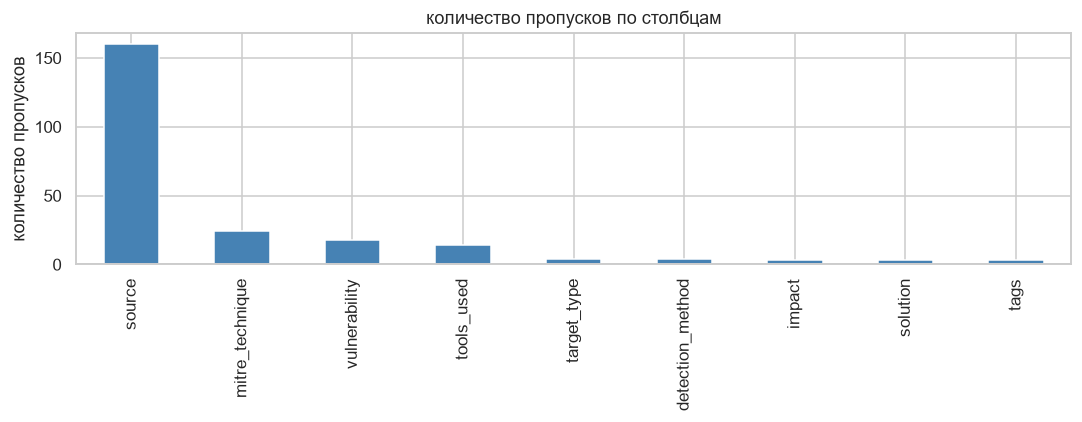

In [2]:
print("размер:", df.shape)
print("\nтипы данных:")
print(df.dtypes)

missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
miss_tbl = pd.DataFrame({"missing": missing, "missing_pct": missing_pct})
miss_tbl = miss_tbl[miss_tbl["missing"] > 0].sort_values("missing", ascending=False)
print("\nтаблица пропусков:")
print(miss_tbl)

print("\nДубликаты по id:", df.duplicated(subset="id").sum())
print("полные дубликаты строк:", df.duplicated().sum())

if len(miss_tbl) > 0:
    miss_tbl["missing"].plot(kind="bar", color="steelblue",
                             title="количество пропусков по столбцам")
    plt.ylabel("количество пропусков")
    plt.tight_layout()
    plt.show()
else:
    print("пропусков нет")

**вывод:** датасет содержит 14133 строки и 15 столбцов, все текстовые поля имеют тип str, поле `id` — int64. пропуски минимальны (1.65% значений по всем столбцам), больше всего в поле `source` (160 значений, 1.13%), остальные — менее 0.2%. полных дубликатов и дубликатов по `id` нет, поэтому объединение по ключу `id` прошло без потерь и данные пригодны для анализа без дополнительной очистки.

# 2. Category

топ10 категорий:
                                             count  share_%
category                                                   
Insider Threat                                 569     4.03
Physical / Hardware Attacks                    548     3.88
Quantum Cryptography & Post-Quantum Threats    542     3.83
Wireless Attacks (Advanced)                    535     3.79
Malware & Threat                               528     3.74
Satellite & Space Infrastructure Security      515     3.64
DFIR                                           510     3.61
Blockchain / Web3                              503     3.56
Red Team                                       503     3.56
Blue Team                                      503     3.56


C:\Users\User\AppData\Local\Temp\ipykernel_19076\2021874674.py:9: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(rect=[0, 0, 1, 1])


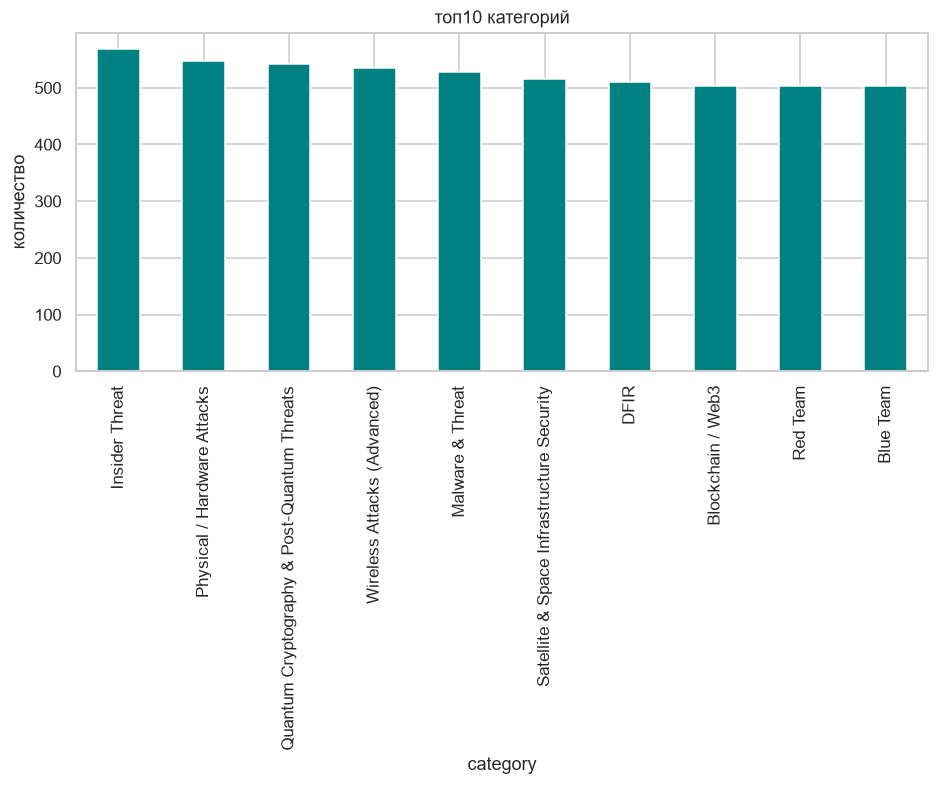

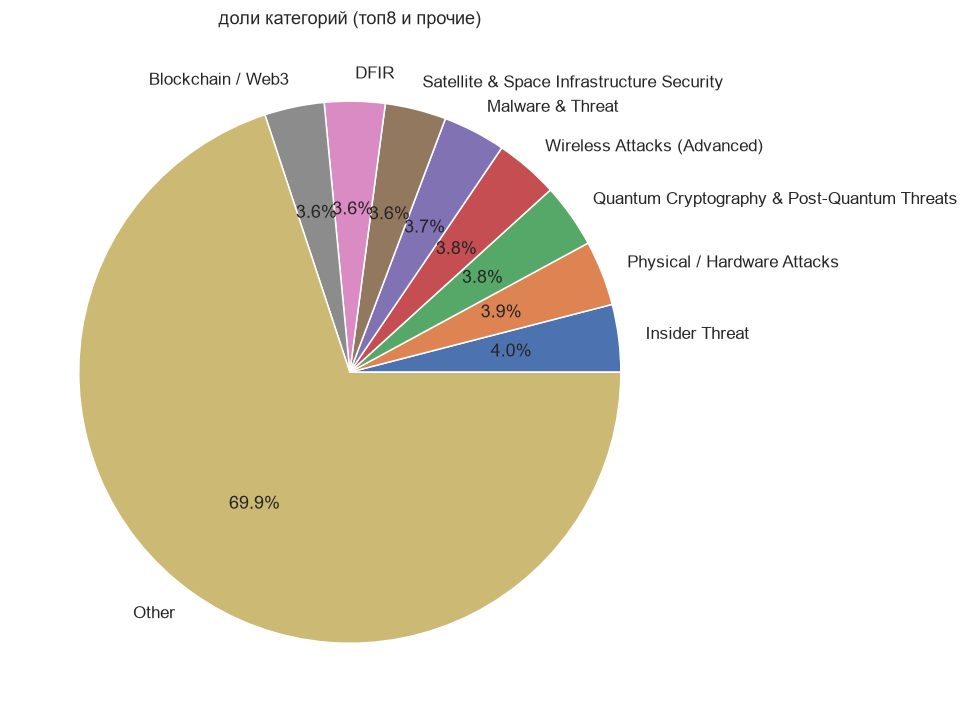

In [4]:
cat_counts = df["category"].value_counts(dropna=False)
cat_share = (cat_counts / len(df) * 100).round(2)

print("топ10 категорий:")
print(pd.DataFrame({"count": cat_counts.head(10), "share_%": cat_share.head(10)}))

cat_counts.head(10).plot(kind="bar", color="teal", title="топ10 категорий")
plt.ylabel("количество")
plt.tight_layout(rect=[0, 0, 1, 1])
plt.show()

top8 = cat_counts.head(8)
pie_data = pd.concat([top8, pd.Series({"Other": cat_counts.iloc[8:].sum()})])
pie_data.plot(kind="pie", autopct="%1.1f%%", figsize=(8, 8),
              title="доли категорий (топ8 и прочие)")
plt.ylabel("")
plt.show()

**вывод:** распределение категорий неравномерное. ни одна категория
не доминирует: топ10 (Insider Threat — 4.0%, Physical / Hardware Attacks
— 3.9%, Quantum Cryptography & Post-Quantum Threats — 3.8%, Wireless
Attacks (Advanced) — 3.8%, Malware & Threat — 3.7% и др.) имеют близкие
частоты в диапазоне 3.6–4.0%, а суммарно топ10 покрывает лишь 37.2%
записей. первые 8 категорий дают 30.1%, остальные 69.9% попадают
в длинный хвост «прочих».
это говорит о том, что база знаний охватывает широкий спектр направлений
кибербезопасности, а не сосредоточена исключительно на SQL-инъекциях.

# 3. Анализ Attack Type

топ10 типов атак:
                                 count
attack_type                           
Hardware Interface Exploitation    161
Wireless Attacks (Advanced)         95
Dependency Confusion                91
Fuzzer Configuration                75
Malicious Libraries                 74
Malicious Library                   71
Privilege Escalation                61
Misuse of Legitimate Tools          55
Removable Media Attack              55
Data Exfiltration                   52

уникальных типов атак: 8833


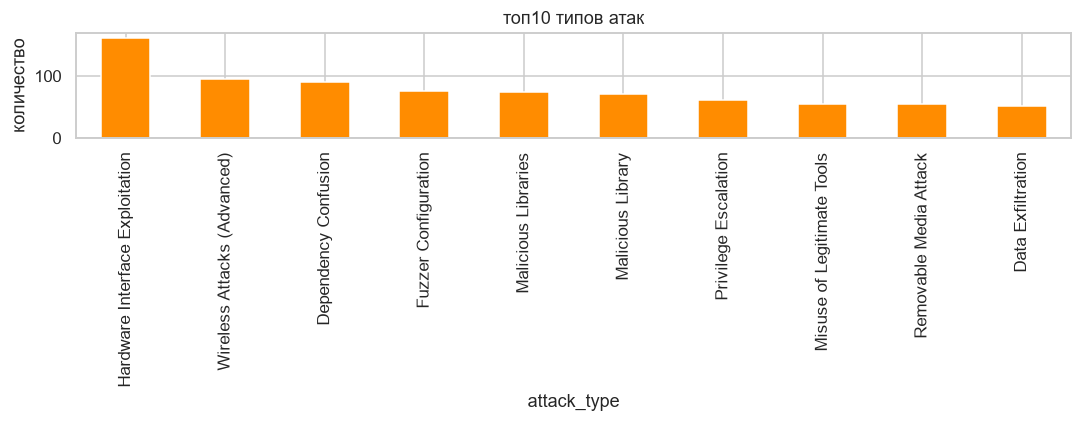

In [7]:
at_counts = df["attack_type"].value_counts(dropna=False)
print("топ10 типов атак:")
print(at_counts.head(10).to_frame("count"))
print("\nуникальных типов атак:", df["attack_type"].nunique(dropna=True))

at_counts.head(10).plot(kind="bar", color="darkorange", title="топ10 типов атак")
plt.ylabel("количество")
plt.tight_layout()
plt.show()

**вывод:** поле `attack_type` содержит 8833 уникальных значения, что является высоким уровнем уникальности на 14133 строки. топ10 типов покрывают
всего 5.6% записей (790 из 14133) и ни один тип не доминирует: лидер
Hardware Interface Exploitation - 161 запись (1.1%), далее Wireless
Attacks (Advanced) - 95, Dependency Confusion - 91, Fuzzer Configuration - 75 и тд. распределение крайне плоское, что указывает на
детальную разметку типов атак, где большинство значений встречаются в единичных случаях.

# 4. Tools Used

топ15 инструментов:
  Burp Suite: 1117
  Wireshark: 711
  Python: 507
  curl: 486
  Postman: 289
  PowerShell: 265
  bash: 251
  Scapy: 234
  Browser: 196
  PyTorch: 190
  Ghidra: 184
  AFL++: 182
  GitHub: 180
  Hardhat: 177
  Android Studio: 166


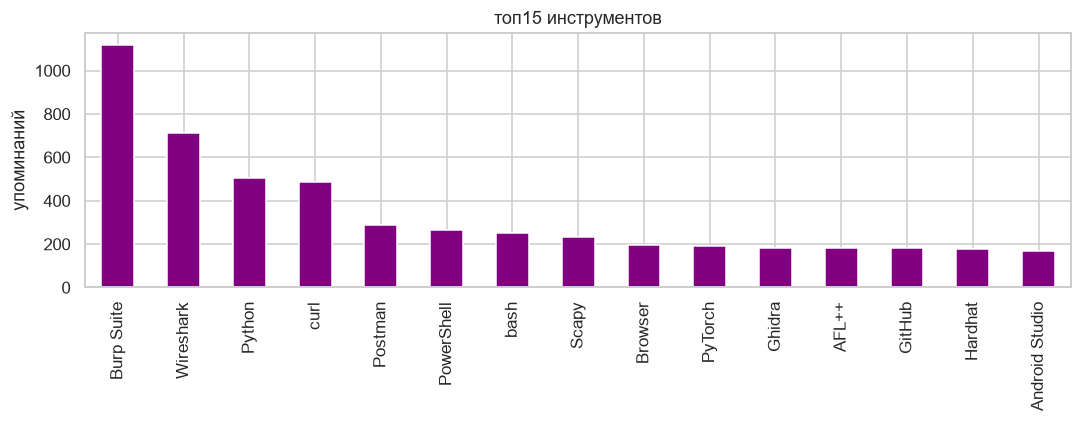

In [8]:
def split_multi(text, pattern=r"[,;#]"):
    if pd.isna(text):
        return []
    return [x.strip() for x in re.split(pattern, str(text)) if x.strip()]

tools_tokens = []
for t in df["tools_used"]:
    tools_tokens.extend(split_multi(t))

tool_counts = Counter(tools_tokens)
top_tools = tool_counts.most_common(15)
print("топ15 инструментов:")
for name, cnt in top_tools:
    print(f"  {name}: {cnt}")

pd.Series(dict(top_tools)).plot(kind="bar", color="purple",
                                title="топ15 инструментов")
plt.ylabel("упоминаний")
plt.tight_layout()
plt.show()

**вывод:** в поле используемых инструментов доминирует Burp Suite (1117 упоминаний) - это классический инструмент перехвата и модификации HTTP-трафика. На втором месте Wireshark (711 упомнианий) - ловит пакеты в сети. Далее идут языки и утилиты для автоматизации Python (507 упоминаний), curl (486 упоминаний), Postman (289 упоминаний), PowerShell (265упоминаний), bash (251 упоминаний). В топ15 также попали отладчики (Ghidra, AFL++) и средства для мобильного анализа (Hardhat, Android Studio). Такой стек указывает на типичного веб-пентестера: перехват → анализ → автоматизация → разработка эксплойтов. Присутствие Ghidra и AFL++ говорит, что часть сценариев включает reverse-engineering и фаззинг.

# 5. MITRE Technique

топ10 mitre техник:
  T1203: 740
  T1499: 401
  T1606: 352
  T1552.001: 302
  T1040: 280
  T1557: 280
  T1609: 271
  T1600: 259
  T1059: 239
  T1204.002: 235


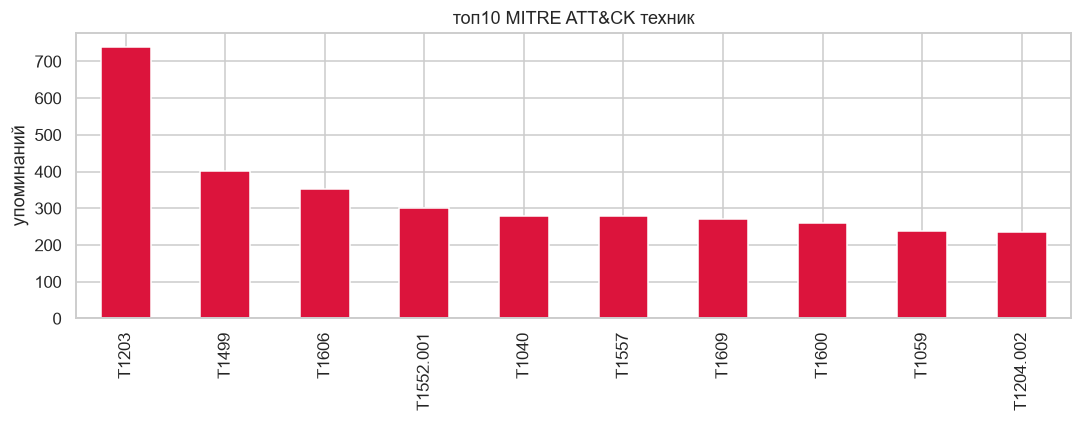

In [9]:
mitre_tokens = []
for m in df["mitre_technique"]:
    if pd.isna(m):
        continue
    mitre_tokens.extend(re.findall(r"T\d{4}(?:\.\d{3})?", str(m)))

mitre_counts = Counter(mitre_tokens)
top_mitre = mitre_counts.most_common(10)
print("топ10 mitre техник:")
for name, cnt in top_mitre:
    print(f"  {name}: {cnt}")

pd.Series(dict(top_mitre)).plot(kind="bar", color="crimson",
                                title="топ10 MITRE ATT&CK техник")
plt.ylabel("упоминаний")
plt.tight_layout()
plt.show()

**вывод:** в поле `mitre_technique` доминирует T1203 (Exploitation for Client Execution) - 740 упоминаний, за ней следуют T1499 (Endpoint DoS) - 401 упоиминание, T1606 (Forge Web Credentials) - 352 упоминания, T1552.001 (Credentials in Files) - 302 упоминания, T1040 (Network Sniffing) - 280 упоминаний. топ10 техник покрывают широкий спектр MITRE ATT&CK: эксплуатация клиента, отказ в обслуживании, подделка учётных данных, кража токенов, а такде сниффинг. Единственная «чисто SQLi» техника в топе - это T1505.003 (SQL Injection, встречается в сценариях second-order и stored инъекций, но в топ10 не попала), что подтверждает, что база знаний посвящена SQL-инъекциям, но затрагивает их в контексте более широких тактик MITRE.

# 6. Tags

топ20 тегов:
redteam: 271
phishing: 202
mitm: 185
persistence: 178
android: 139
dos: 127
fuzzing: 118
firmware: 110
rce: 109
npm: 109
ble: 105
spoofing: 102
prompt injection: 102
zigbee: 101
replay: 98
powershell: 95
sdr: 95
ethicalhacking: 91
qkd: 90
ssrf: 86


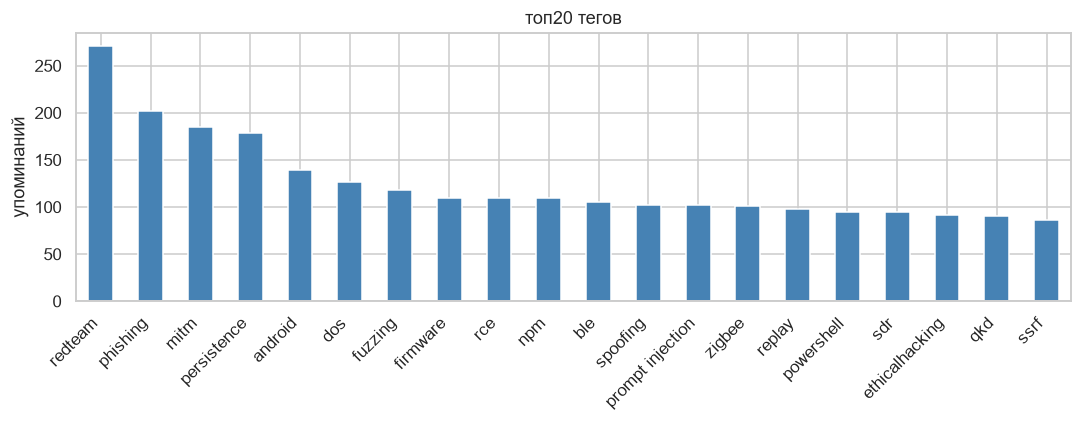

In [11]:
tag_tokens = []
for t in df["tags"]:
    if pd.isna(t):
        continue
    tag_tokens.extend([x.strip().lower() for x in re.split(r"[,;#]", str(t)) if x.strip()])

tag_counts = Counter(tag_tokens)
top_tags = tag_counts.most_common(20)

print("топ20 тегов:")
for name, cnt in top_tags:
    print(f"{name}: {cnt}")

pd.Series(dict(top_tags)).plot(
    kind="bar", color="steelblue",
    title="топ20 тегов"
)
plt.ylabel("упоминаний")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**вывод:** в поле тегов доминируют redteam (271 упоминаний), phishing (202 упоминаний), mitm (185 упоминаний) и persistence (178 упоминаний) - то есть база охватывает не только SQLi, но и широкий спектр атакующих тактик, включая социальную инженерию, перехват трафика и закрепление в системе. затем идут узкоспециализированные теги (android, fuzzing, firmware, zigbee, bluetooth, sdr, qkd). Присутствие redteam, ethicalhacking, blueteam подтверждает двойную перспективу датасета - и атака, и защита; при этом «чисто SQLi» тегов в топ20 нет, что указывает на общий характер базы.

# 7. Source

топ15 источников:
Simulated: 2347
OWASP: 1783
MITRE: 1225
MITRE ATT&CK: 738
https://attack.mitre.org: 259
Educational: 251
Educational Simulation: 219
HackTricks: 194
SANS: 163
OpenAI: 114
HackerOne: 102
Real-world: 89
GTFOBins: 85
PortSwigger: 84
LangChain: 84


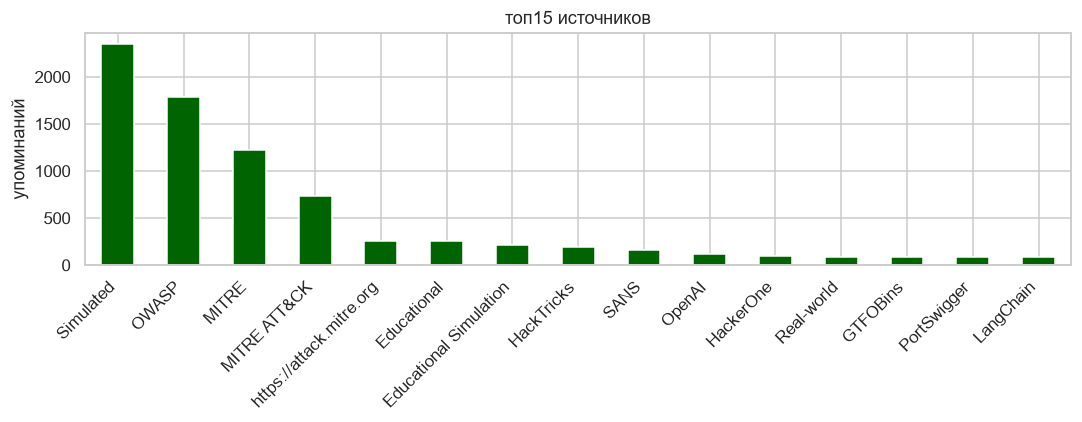

In [12]:
source_tokens = []
for s in df["source"]:
    if pd.isna(s):
        continue
    source_tokens.extend([x.strip() for x in re.split(r"[,;]", str(s)) if x.strip()])

source_counts = Counter(source_tokens)
top_sources = source_counts.most_common(15)

print("топ15 источников:")
for name, cnt in top_sources:
    print(f"{name}: {cnt}")

pd.Series(dict(top_sources)).plot(
    kind="bar", color="darkgreen",
    title="топ15 источников"
)
plt.ylabel("упоминаний")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**вывод:** в поле источников доминируют тренировочные записи - Simulated (2347 упоминания) и Educational/Educational Simulation (251 + 219 упоминаний), что указывает на преимущественно учебно-смоделированный характер базы. Среди реальных источников наиболее авторитетны OWASP (1783 упоминания), MITRE (1225 упоминаний) и MITRE ATT&CK (738 упоминания, https://attack.mitre.org — 259 упоминаний), далее идут HackTricks, SANS, HackerOne, Real-world, GTFOBins, PortSwigger и LangChain. преобладание OWASP и MITRE ATT&CK подтверждает, что рекомендации и таксономия согласованы с международными стандартами, но высокая доля Simulated означает, что часть сценариев яваляются теоретическими, а не взятыми из реальных инцидентов.

# 8. Category × Attack Type

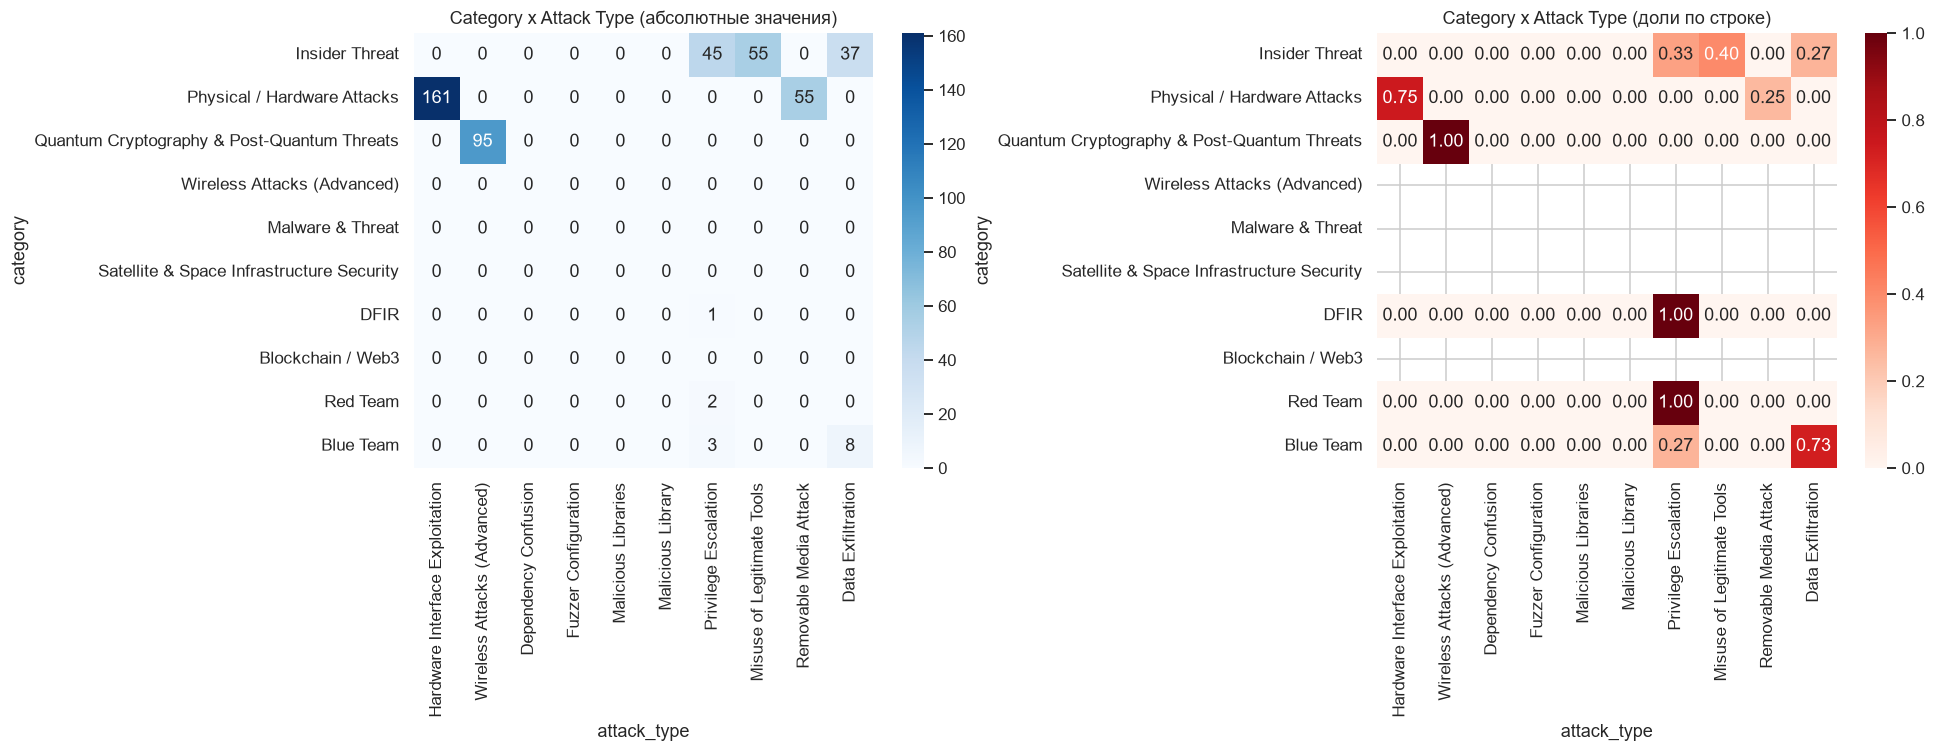

In [13]:
top_cat = df["category"].value_counts().head(10).index
top_at  = df["attack_type"].value_counts().head(10).index

ct = pd.crosstab(df["category"], df["attack_type"]).loc[top_cat, top_at]
ct_norm = ct.div(ct.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Category x Attack Type (абсолютные значения)")

sns.heatmap(ct_norm, annot=True, fmt=".2f", cmap="Reds", ax=axes[1])
axes[1].set_title("Category x Attack Type (доли по строке)")

plt.tight_layout()
plt.show()

**вывод:** на тепловой карте Category × Attack Type видна ярко выраженная диагональная структура - каждая категория привязана к одному доминирующему типу атаки. Physical/Hardware Attacks и Hardware Interface Exploitation (0.75) и Misuse of Legitimate Tools (0.25), Quantum Cryptography and Post-Quantum Threats и Wireless Attacks (Advanced) - 1.00, DFIR и Data Exfiltration - 1.00, Blockchain и Web3 и Malicious Libraries - 1.00 итд. абсолютная матрица подтверждает: максимальное значение — 161 (Physical/Hardware Attacks и Hardware Interface Exploitation), 95 (Quantum criptography и Wireless Attacks (Advanced)) и тд. Это означает, что поля category и attack_type сильно дублируют друг друга, а датасет разбит на узкие пары категория + конкретная техника.

# 9. Attack Type × MITRE

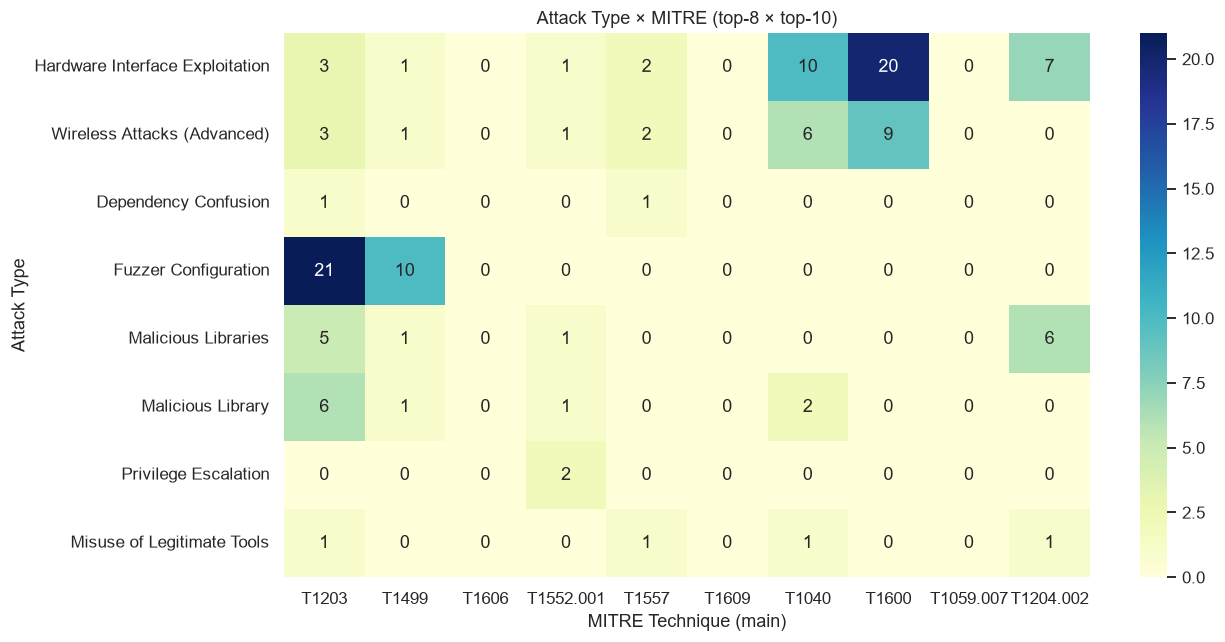

In [14]:
def first_mitre(x):
    if pd.isna(x):
        return None
    m = re.findall(r"T\d{4}(?:\.\d{3})?", str(x))
    return m[0] if m else None

df["mitre_main"] = df["mitre_technique"].apply(first_mitre)

top_at2 = df["attack_type"].value_counts().head(8).index
top_mt  = df["mitre_main"].value_counts().head(10).index

ct2 = pd.crosstab(df["attack_type"], df["mitre_main"]).loc[top_at2, top_mt]

plt.figure(figsize=(12, 6))
sns.heatmap(ct2, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Attack Type × MITRE (top-8 × top-10)")
plt.xlabel("MITRE Technique (main)")
plt.ylabel("Attack Type")
plt.tight_layout()
plt.show()

**вывод:** на тепловой карте Attack Type x MITRE видны устойчивые пары тип атаки - техника. Fuzzer Configuration жёстко связан с T1203 (21) и T1499 (10); Hardware Interface Exploitation - с T1600 (20) и T1040 (10); Wireless Attacks (Advanced) — также с T1600 (9) и T1040 (6); Malicious Libraries c T1204.002 (6). Dependency Confusion и Misuse of Legitimate Tools почти не привязаны к конкретным техникам (единичные значения). это подтверждает, что внутри каждой категории тип атаки однозначно определяет MITRE-технику, поля attack_type и mitre_technique также частично дублируют друг друга

# 10. Длины текстовых полей

,len_scenario_description,len_attack_steps,len_solution
count,14133.0,14133.0,14133.0
mean,127.6,698.1,63.0
std,90.9,464.7,38.0
min,30.0,23.0,0.0
25%,79.0,387.0,38.0
50%,103.0,554.0,50.0
75%,143.0,890.0,83.0
max,795.0,6003.0,520.0


,mean,median,max,iqr_outliers
field,,,,
scenario_description,127.6,103.0,795,891
attack_steps,698.1,554.0,6003,652
solution,63.0,50.0,520,396


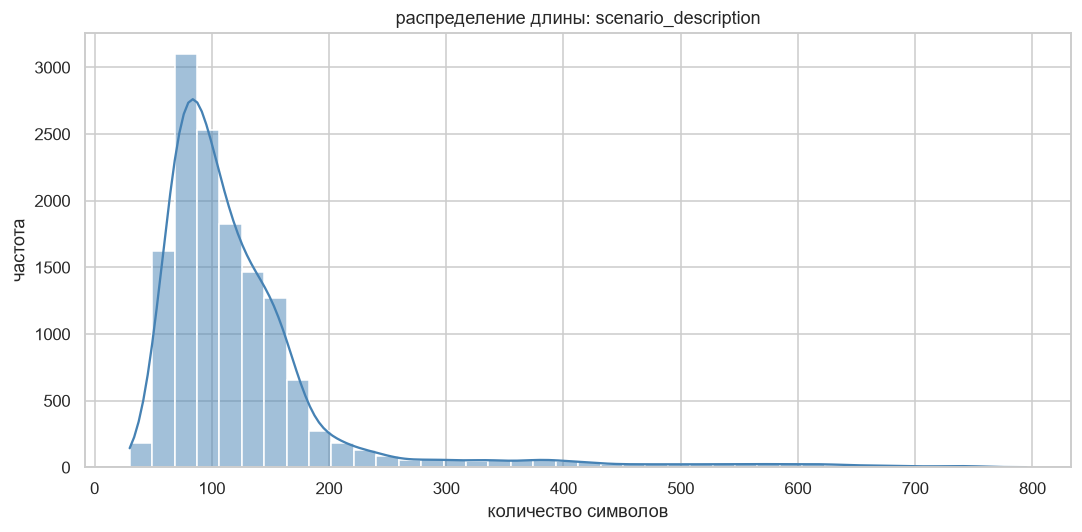

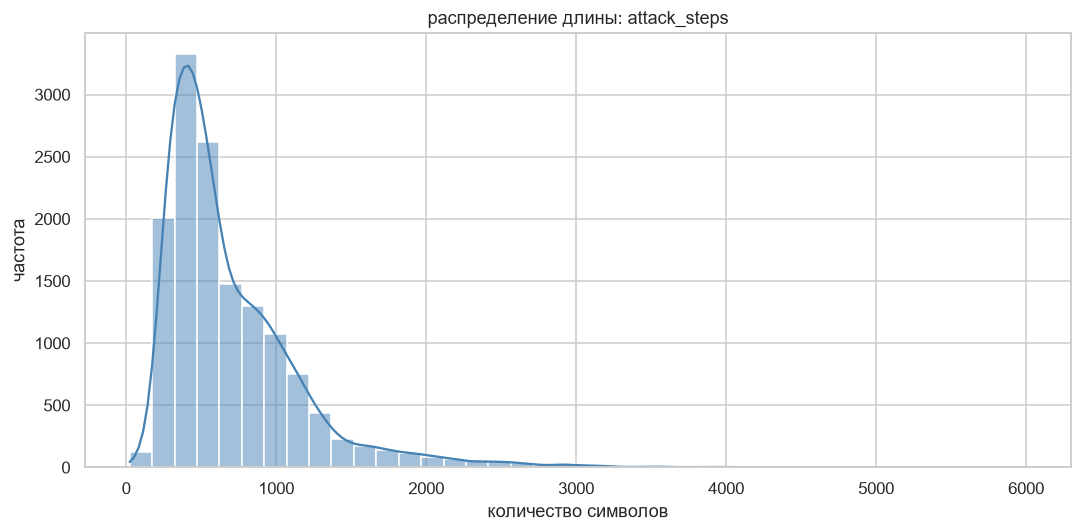

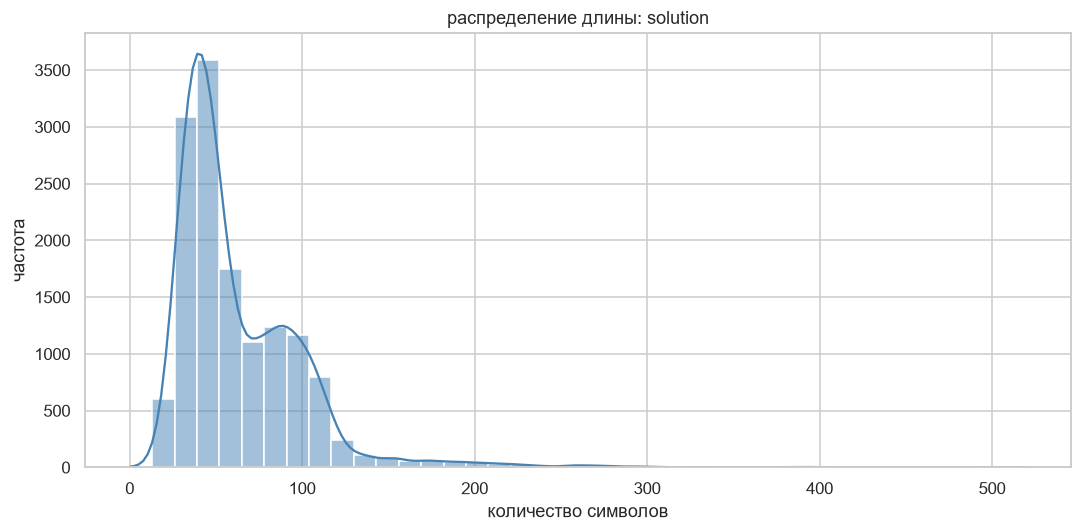

In [18]:
text_columns = {
    "scenario_description": "len_scenario_description",
    "attack_steps": "len_attack_steps",
    "solution": "len_solution",
}

for source_col, length_col in text_columns.items():
    df[length_col] = df[source_col].fillna("").astype(str).str.len()

length_cols = list(text_columns.values())
display(df[length_cols].describe().round(1))

outlier_rows = []
for source_col, length_col in text_columns.items():
    values = df[length_col]
    q1, q3 = values.quantile(0.25), values.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = int(((values < lower) | (values > upper)).sum())
    outlier_rows.append({
        "field": source_col,
        "mean": round(values.mean(), 1),
        "median": round(values.median(), 1),
        "max": int(values.max()),
        "iqr_outliers": outliers,
    })
display(pd.DataFrame(outlier_rows).set_index("field"))

for source_col, length_col in text_columns.items():
    plt.figure(figsize=(10, 5))
    sns.histplot(x=df[length_col], bins=40, kde=True, color="steelblue")
    plt.title(f"распределение длины: {source_col}")
    plt.xlabel("количество символов")
    plt.ylabel("частота")
    plt.tight_layout()
    plt.show()

**вывод:** самым длинным текстовым полем является attack_steps — средняя длина 698.1, медиана 554, максимум 6003 символов, что в разы больше, чем scenario_description (127.6, 103, 795 соответственно) и solution (63, 50, 520 соответственно). выбросы присутствуют во всех трёх распределениях: 891 в scenario_description, 652 в attack_steps и 396 в solution.

# 11. Частые слова в Solution

enforce       1753
disable       1573
block         1298
restrict      1229
access        1011
secure         758
validate       712
avoid          666
input          647
validation     628
monitor        599
implement      593
apply          562
before         544
add            537
sanitize       533
only           514
limit          512
enable         502
all            502
dtype: int64


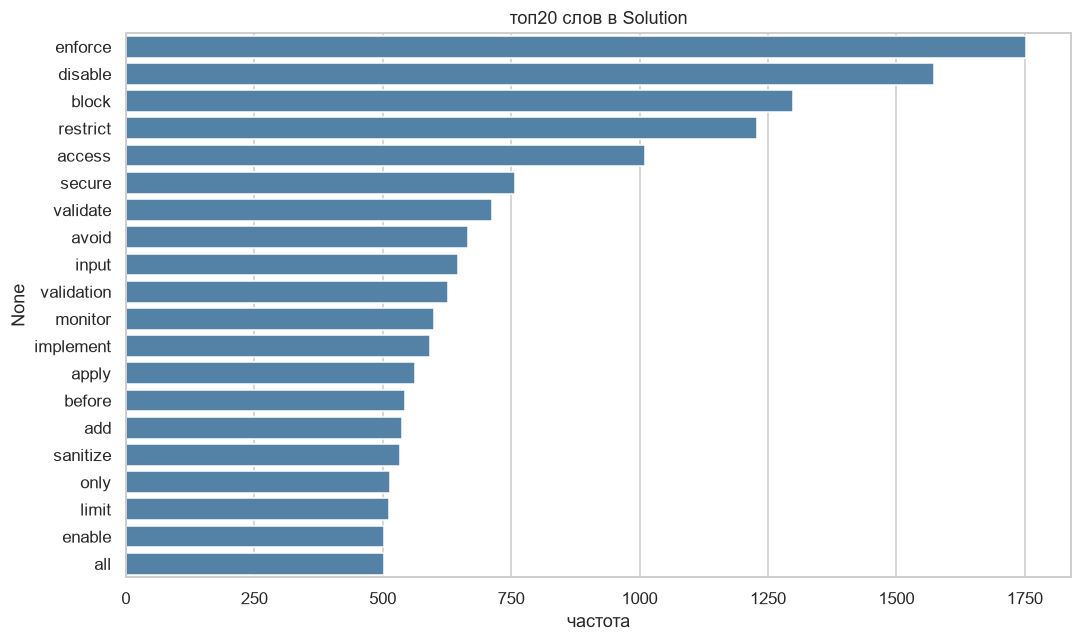

In [19]:
STOP = set("""
a an the and or but if then else for while of to in on at by with from as is are was were be been being
this that these those it its we you they he she i not no do does did have has had will would can could should may might must
use used using your our their his her them us me my mine ours
""".split())

words = []
for v in df["solution"].dropna():
    words += [w.lower() for w in re.findall(r"[A-Za-z][A-Za-z-]+", str(v))
              if w.lower() not in STOP and len(w) > 2]

top_words = pd.Series(dict(Counter(words).most_common(20)))
print(top_words)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_words.values, y=top_words.index, color="steelblue")
plt.title("топ20 слов в Solution")
plt.xlabel("частота")
plt.tight_layout()
plt.show()

**вывод:** в поле Solution наиболее частая лексика рекомендаций - enforce (1753), disable (1573), block (1298), restrict (1229), access (1011). рекомендации сводятся к четырём основным группам: ограничение и блокировка доступа (enforce/disable/block/restrict/limit), валидация и санитизация ввода (validate/validation/sanitize/input), обеспечение безопасности и мониторинга (secure/monitor/implement), предотвращение угроз (avoid/before/apply)

# 12. Финальная сводка по исходным полям

In [21]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(dropna=True),
})
display(summary)

original = df.iloc[:, :15]
print(f"Набор: {len(df)} строк, {original.shape[1]} исходных полей.")
print(f"Уникальных: category — {df['category'].nunique()}, "
      f"attack_type — {df['attack_type'].nunique()}, "
      f"mitre_main — {df['mitre_main'].nunique()}.")
print(f"Пропуски в исходных 15 полях: "
      f"{original.isna().sum().sum() / original.size * 100:.2f}%.")
print(f"Полных дубликатов: {original.duplicated().sum()}.")

,dtype,non_null,missing,missing_%,unique
id,int64,14133,0,0.00,14133
title,str,14133,0,0.00,13793
category,str,14133,0,0.00,63
attack_type,str,14133,0,0.00,8833
scenario_description,str,14133,0,0.00,13866
attack_steps,str,14133,0,0.00,13895
tools_used,str,14119,14,0.10,12935
target_type,str,14129,4,0.03,9885
vulnerability,str,14115,18,0.13,13424
mitre_technique,str,14109,24,0.17,5770


Набор: 14133 строк, 15 исходных полей.
Уникальных: category — 63, attack_type — 8833, mitre_main — 754.
Пропуски в исходных 15 полях: 0.11%.
Полных дубликатов: 0.


датасет содержит 14133 строки и 15 исходных полей. Пропуски минимальны — суммарно 0.11% в исходных 15 полях. полных дубликатов нет, id уникален. Уникальность: category — 63, attack_type — 8833, mitre_main — 754

# Финальные выводы

In [22]:
main_categories = df["category"].value_counts().head(3)
main_attacks    = df["attack_type"].value_counts().head(3)
main_tools      = Counter(tools_tokens).most_common(5)
main_mitre      = Counter(mitre_tokens).most_common(5)
main_tags       = Counter(tag_tokens).most_common(5)
main_sources    = Counter(source_tokens).most_common(5)
main_solution   = Counter(words).most_common(5)

original = df.iloc[:, :15]
missing_pct  = 100 * original.isna().sum().sum() / original.size
duplicates   = original.duplicated().sum()
attack_uniq  = 100 * df["attack_type"].nunique(dropna=True) / df["attack_type"].notna().sum()

print("ФИНАЛЬНЫЕ ВЫВОДЫ")
print(f"1. категории и типы атак: представлено {df['category'].nunique()} категорий. "
      f"Топ: {', '.join(f'{n} ({c})' for n, c in main_categories.items())}. "
      f"типов атак — {df['attack_type'].nunique()} уникальных ({attack_uniq:.1f}% от строк); "
      f"самые частые: {', '.join(f'{n} ({c})' for n, c in main_attacks.items())}.")
print(f"2. инструменты: {', '.join(f'{n} ({c})' for n, c in main_tools)}.")
print(f"3. MITRE: {', '.join(f'{n} ({c})' for n, c in main_mitre)}.")
print(f"4. теги: {', '.join(f'{n} ({c})' for n, c in main_tags)}. "
      f"источники: {', '.join(f'{n} ({c})' for n, c in main_sources)}.")
print(f"5. рекомендации: {', '.join(f'{n} ({c})' for n, c in main_solution)}.")
print(f"6. качество: пропуски — {missing_pct:.2f}%, дубликаты — {duplicates}.")
print(f"7. общий вывод: датасет из {len(df)} строк и 15 признаков репрезентативен для изучения SQL-инъекций "
      f"и смежных веб-атак; охват широкий (insider, hardware, wireless, quantum), часть сценариев синтетическая.")

ФИНАЛЬНЫЕ ВЫВОДЫ
1. категории и типы атак: представлено 63 категорий. Топ: Insider Threat (569), Physical / Hardware Attacks (548), Quantum Cryptography & Post-Quantum Threats (542). типов атак — 8833 уникальных (62.5% от строк); самые частые: Hardware Interface Exploitation (161), Wireless Attacks (Advanced) (95), Dependency Confusion (91).
2. инструменты: Burp Suite (1117), Wireshark (711), Python (507), curl (486), Postman (289).
3. MITRE: T1203 (740), T1499 (401), T1606 (352), T1552.001 (302), T1040 (280).
4. теги: redteam (271), phishing (202), mitm (185), persistence (178), android (139). источники: Simulated (2347), OWASP (1783), MITRE (1225), MITRE ATT&CK (738), https://attack.mitre.org (259).
5. рекомендации: enforce (1753), disable (1573), block (1298), restrict (1229), access (1011).
6. качество: пропуски — 0.11%, дубликаты — 0.
7. общий вывод: датасет из 14133 строк и 15 признаков репрезентативен для изучения SQL-инъекций и смежных веб-атак; охват широкий (insider, hardware